<a href="https://colab.research.google.com/github/lana-jo/smart-waste-management/blob/main/waste_classification_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
import os
import shutil

# 1. Download dataset langsung dari Kaggle
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
src_base = os.path.join(path, "garbage_classification")

# Bilamana struktur ekstraksi berada satu level di dalam/luar
if not os.path.exists(src_base):
    for root, dirs, _ in os.walk(path):
        if "biological" in dirs and "plastic" in dirs:
            src_base = root
            break

# 2. Mapping ke 3 kelas sesuai spesifikasi proyek
mapping = {
    "biological": "Organic Waste",
    "plastic": "Plastic Waste",
    "paper": "Paper Waste"
}

dataset_dir = "dataset"
if os.path.exists(dataset_dir):
    shutil.rmtree(dataset_dir)
os.makedirs(dataset_dir, exist_ok=True)

valid_ext = (".jpg", ".jpeg", ".png")

for src_folder, target_name in mapping.items():
    src_dir = os.path.join(src_base, src_folder)
    dst_dir = os.path.join(dataset_dir, target_name)
    os.makedirs(dst_dir, exist_ok=True)

    # Urutkan nama file agar hasil kurasi konsisten dan ambil 100 gambar pertama
    images = sorted([f for f in os.listdir(src_dir) if f.lower().endswith(valid_ext)])[:100]
    for img in images:
        shutil.copy(os.path.join(src_dir, img), os.path.join(dst_dir, img))
    print(f"[OK] Kelas '{target_name}': {len(os.listdir(dst_dir))} gambar berhasil disalin.")

total_imgs = sum(len(files) for _, _, files in os.walk(dataset_dir))
print(f"\nTotal keseluruhan dataset: {total_imgs} gambar (Syarat minimal: 150 gambar).")

Using Colab cache for faster access to the 'garbage-classification' dataset.
[OK] Kelas 'Organic Waste': 100 gambar berhasil disalin.
[OK] Kelas 'Plastic Waste': 100 gambar berhasil disalin.
[OK] Kelas 'Paper Waste': 100 gambar berhasil disalin.

Total keseluruhan dataset: 300 gambar (Syarat minimal: 150 gambar).


In [2]:
import json
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split

# Set random seed agar hasil akurasi stabil dan dapat direproduksi
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
CLASS_NAMES = ["Organic Waste", "Paper Waste", "Plastic Waste"]

# Simpan urutan kelas ke JSON untuk digunakan di backend FastAPI
with open("class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)

X_data = []
y_data = []

for label_idx, class_name in enumerate(CLASS_NAMES):
    folder_path = os.path.join(dataset_dir, class_name)
    for img_name in sorted(os.listdir(folder_path)):
        img_path = os.path.join(folder_path, img_name)
        with Image.open(img_path) as img:
            img_rgb = img.convert("RGB").resize(IMG_SIZE)
            X_data.append(np.array(img_rgb, dtype=np.float32))
            y_data.append(label_idx)

X_data = np.array(X_data, dtype=np.float32)
y_data = np.array(y_data, dtype=np.int32)

# Pembagian 80% Training (240 gambar) & 20% Testing (60 gambar) secara merata per kelas
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data,
    test_size=0.20,
    stratify=y_data,
    random_state=SEED
)

# One-hot encoding untuk label (3 kelas)
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=len(CLASS_NAMES))
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes=len(CLASS_NAMES))

print(f"Urutan Kelas   : {CLASS_NAMES}")
print(f"Data Training  : {X_train.shape[0]} gambar | Shape: {X_train.shape}")
print(f"Data Testing   : {X_test.shape[0]} gambar  | Shape: {X_test.shape}")

Urutan Kelas   : ['Organic Waste', 'Paper Waste', 'Plastic Waste']
Data Training  : 240 gambar | Shape: (240, 224, 224, 3)
Data Testing   : 60 gambar  | Shape: (60, 224, 224, 3)


In [3]:
from tensorflow.keras import layers, models

BATCH_SIZE = 16

# 1. Layer Normalisasi & Augmentasi (Ditambah RandomZoom 0.2 dari skrip kedua)
rescale_layer = layers.Rescaling(1./255)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
], name="data_augmentation")

# Normalisasi [0, 255] -> [0.0, 1.0]
X_train_norm = rescale_layer(X_train).numpy()
X_test_norm = rescale_layer(X_test).numpy()

train_ds = tf.data.Dataset.from_tensor_slices((X_train_norm, y_train_cat))
train_ds = (
    train_ds
    .shuffle(buffer_size=240, seed=SEED)
    .batch(BATCH_SIZE)
    .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = tf.data.Dataset.from_tensor_slices((X_test_norm, y_test_cat))
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# 2. Arsitektur MobileNetV2 + Dense(128) Hybrid Head
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3), name="input_image")
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
x = layers.Dense(128, activation="relu", name="feature_dense")(x)
x = layers.Dropout(0.3, name="dropout")(x)
outputs = layers.Dense(3, activation="softmax", name="output_probabilities")(x)

model = models.Model(inputs=inputs, outputs=outputs, name="SmartWaste_MobileNetV2")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "SmartWaste_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_dense (Dense)           │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_probabilities (Dense)    │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 23s 726ms/step - accuracy: 0.7375 - loss: 0.7034 - val_accuracy: 0.9500 - val_loss: 0.1901 - learning_rate: 0.0010
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.9208 - loss: 0.1924 - val_accuracy: 0.9667 - val_loss: 0.1060 - learning_rate: 0.0010
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 144ms/step - accuracy: 0.9542 - loss: 0.1050 - val_accuracy: 0.9000 - val_loss: 0.1538 - learning_rate: 0.0010
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.9458 - loss: 0.1095 - val_accuracy: 0.9667 - val_loss: 0.1046 - learning_rate: 0.0010
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 134ms/step - accuracy: 0.9792 - loss: 0.0683 - val_accuracy: 0.9500 - val_loss: 0.0936 - learning_rate: 0.0010
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 139ms/step - accuracy: 0.9708 - loss: 0.0705 - val_accuracy: 0.9833 - val_loss: 0.0678 - learning_rate: 0.0010
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.9792 - loss: 0.0522 -

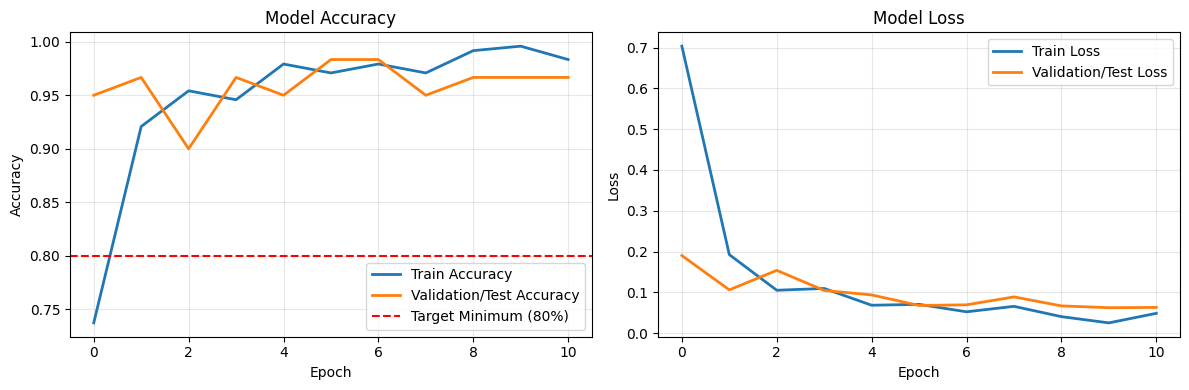

In [4]:
import matplotlib.pyplot as plt

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Plot grafik Akurasi & Loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy", linewidth=2)
plt.plot(history.history["val_accuracy"], label="Validation/Test Accuracy", linewidth=2)
plt.axhline(y=0.80, color="r", linestyle="--", label="Target Minimum (80%)")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss", linewidth=2)
plt.plot(history.history["val_loss"], label="Validation/Test Loss", linewidth=2)
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_history.png", dpi=300)
plt.show()

FINAL TEST ACCURACY : 98.33% (Syarat Minimum: 80.00%)

CLASSIFICATION REPORT:

               precision    recall  f1-score   support

Organic Waste     0.9524    1.0000    0.9756        20
  Paper Waste     1.0000    0.9500    0.9744        20
Plastic Waste     1.0000    1.0000    1.0000        20

     accuracy                         0.9833        60
    macro avg     0.9841    0.9833    0.9833        60
 weighted avg     0.9841    0.9833    0.9833        60



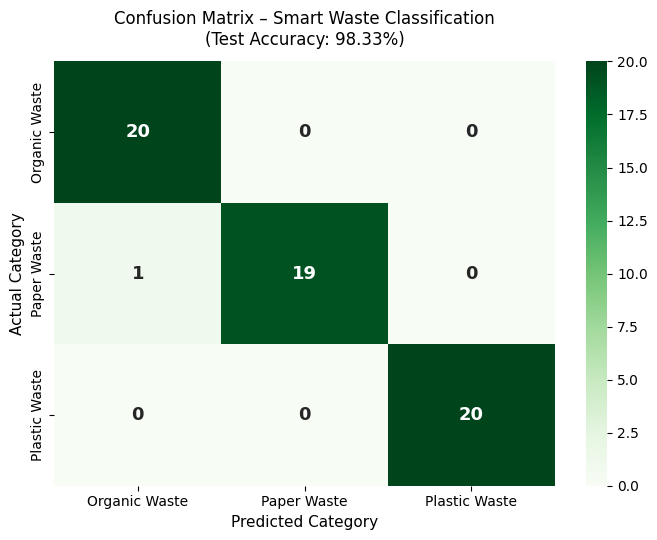

In [5]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Prediksi pada 60 data testing
y_pred_probs = model.predict(X_test_norm, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Hitung Test Accuracy
test_acc = accuracy_score(y_test, y_pred)
print("=" * 60)
print(f"FINAL TEST ACCURACY : {test_acc * 100:.2f}% (Syarat Minimum: 80.00%)")
print("=" * 60)

# 3. Cetak & Simpan Classification Report
report_str = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4)
print("\nCLASSIFICATION REPORT:\n")
print(report_str)

with open("classification_report.txt", "w") as f:
    f.write(f"Final Test Accuracy: {test_acc * 100:.2f}%\n\n")
    f.write("Classification Report:\n")
    f.write(report_str)

# 4. Plot & Simpan Confusion Matrix (confusion_matrix.png)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    annot_kws={"size": 13, "weight": "bold"}
)
plt.title(f"Confusion Matrix – Smart Waste Classification\n(Test Accuracy: {test_acc * 100:.2f}%)", fontsize=12, pad=12)
plt.xlabel("Predicted Category", fontsize=11)
plt.ylabel("Actual Category", fontsize=11)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [6]:
def predict_single_image(image_path: str):
    with Image.open(image_path) as img:
        img_resized = img.convert("RGB").resize((224, 224))

    # Normalisasi [0, 255] -> [0.0, 1.0] dan tambah dimensi batch (1, 224, 224, 3)
    img_array = np.array(img_resized, dtype=np.float32) / 255.0
    img_batch = np.expand_dims(img_array, axis=0)

    probs = model.predict(img_batch, verbose=0)[0]
    best_idx = int(np.argmax(probs))

    result = {
        "predicted_class": CLASS_NAMES[best_idx],
        "confidence": round(float(probs[best_idx]), 4),
        "probabilities": {
            CLASS_NAMES[i]: round(float(probs[i]), 4)
            for i in range(len(CLASS_NAMES))
        }
    }
    return result

# Uji coba pada salah satu gambar di folder Plastic Waste
sample_img = os.path.join(dataset_dir, "Plastic Waste", os.listdir(os.path.join(dataset_dir, "Plastic Waste"))[0])
print(f"Menguji file: {sample_img}")
print(json.dumps(predict_single_image(sample_img), indent=2))

Menguji file: dataset/Plastic Waste/plastic141.jpg
{
  "predicted_class": "Plastic Waste",
  "confidence": 0.968,
  "probabilities": {
    "Organic Waste": 0.0001,
    "Paper Waste": 0.0319,
    "Plastic Waste": 0.968
  }
}


In [7]:
import zipfile
from google.colab import files

# 1. Simpan model dalam format .keras (utama) dan .h5 (cadangan)
model.save("waste_model.keras")
model.save("waste_model.h5")
print("[OK] Model berhasil disimpan: waste_model.keras & waste_model.h5")

# 2. Zip folder dataset (300 gambar)
shutil.make_archive("dataset", "zip", ".", "dataset")
print("[OK] Dataset berhasil di-zip: dataset.zip")

# 3. Bundel seluruh deliverables Phase 2 ke dalam satu file ZIP agar mudah diunduh
bundle_name = "phase2_ml_deliverables.zip"
files_to_bundle = [
    "waste_model.keras",
    "waste_model.h5",
    "class_names.json",
    "confusion_matrix.png",
    "training_history.png",
    "classification_report.txt",
    "dataset.zip"
]

with zipfile.ZipFile(bundle_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_item in files_to_bundle:
        if os.path.exists(file_item):
            zipf.write(file_item)

print(f"\n[SELESAI] Mengunduh {bundle_name}...")
files.download(bundle_name)

[OK] Model berhasil disimpan: waste_model.keras & waste_model.h5
[OK] Dataset berhasil di-zip: dataset.zip

[SELESAI] Mengunduh phase2_ml_deliverables.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>